In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# High level imports
from wrtds_py import WRTDS, WRTDSK

# Data
Import the data from the reference `data.csv` in the `tests` folder. The data are nitrate concentrations in mg/L for the Grand River near the neighborhood of Doon in Kitchener, Ontario, Canada. The nitrate data are from Station ID 803745 from DataStream Canada and it has been co-located with the HyDAT gauge 02GA048 to include a record of streamflow in m3/s.

Here we read the data and separate the columns into the DataFrames `df_wq` and `df_q` for the nitrate concentrations and streamflow, respectively.

In [2]:
df = pd.read_csv('../tests/data.csv', index_col=0, parse_dates=True)

df_q = df[['Q']].copy()
df_wq = df.dropna(subset=['Conc', 'Uncen'])
df_wq['Q'] = np.nan
for date in df_wq.index:
    df_wq.loc[date, 'Q'] = df_q.loc[date, 'Q']

# Re-cast the censorship flag to integer
df_wq['Uncen'] = df_wq['Uncen'].astype(int)

# Prepare the data summary table
num_wq, num_q = df_wq.shape[0], df_q.shape[0]
min_date_wq, max_date_wq = df_wq.index.min().strftime('%d-%m-%Y'), df_wq.index.max().strftime('%d-%m-%Y')
min_date_q, max_date_q = df_q.index.min().strftime('%d-%m-%Y'), df_q.index.max().strftime('%d-%m-%Y')

# Print summary table
print(f"{'Data':<15} | {'Start Date':<12} | {'End Date':<12} | {'Num Records':<12}")
print(f"{'-'*15} | {'-'*12} | {'-'*12} | {'-'*12}")
print(f"{'Water Quality':<15} | {min_date_wq:<12} | {max_date_wq:<12} | {num_wq:<12}")
print(f"{'Streamflow':<15} | {min_date_q:<12} | {max_date_q:<12} | {num_q:<12}")

Data            | Start Date   | End Date     | Num Records 
--------------- | ------------ | ------------ | ------------
Water Quality   | 23-03-2007   | 03-12-2016   | 75          
Streamflow      | 23-05-2006   | 31-12-2024   | 6798        


# Models

## WRTDS

We first instantiate the base WRTDS model with the default parameters and fit it to the data. The model is then used to predict the nitrate concentrations for the `df_wq` DataFrame to calculate the error (as `RMSE`) between the observed and predicted values. Then the model is used to predict the nitrate concentrations for the entire streamflow record in `df_q`.

In [3]:
model = WRTDS()
model = model.fit(df_wq, df_q, verbose=True)

Fitting WRTDS: 100%|##########| 4186/4186 [00:06<00:00, 647.36it/s]
/Users/manuel/Projects/wrtds-py/src/wrtds_py/models/classic.py:95: UserWarning: Adaptive window expansion triggered for 4186 nodes.
  warnings.warn(f"Adaptive window expansion triggered for {expansion_warnings} nodes.")


In [4]:
y_hat_wq = model.predict(df_wq)
rmse = np.sqrt(np.mean((y_hat_wq['ConcHat'] - df_wq['Conc'])**2))
print(f'RMSE = {rmse:.2f} mg/L')

RMSE = 0.71 mg/L


In [5]:
y_hat_q = model.predict(df_q)

Plot the observed and predicted nitrate concentrations

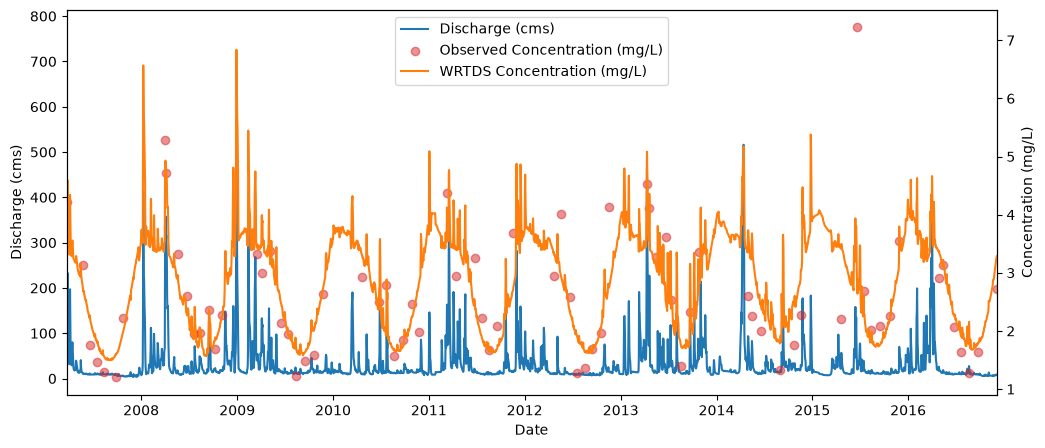

In [6]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(y_hat_q.index, y_hat_q['Q'], label='Discharge (cms)')
ax2 = ax.twinx()
ax2.scatter(df_wq.index, df_wq['Conc'], label='Observed Concentration (mg/L)', color='tab:red', alpha=0.5)
ax2.plot(y_hat_q.index, y_hat_q['ConcHat'], label='WRTDS Concentration (mg/L)', color='tab:orange')
ax.set_xlabel('Date')
ax.set_ylabel('Discharge (cms)')
ax2.set_ylabel('Concentration (mg/L)')
for sub_ax in [ax, ax2]:
    sub_ax.set_xlim(df_wq.index.min(), df_wq.index.max())
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2)
plt.show()

## WRTDS-K
Having a fitted base WRTDS model, we can now instantiate the WRTDS-K model to adjust the predictions made by the base model. The WRTDS-K model is fitted to the residuals of the base model and then used to predict the nitrate concentrations for the entire streamflow record in `df_q`. We again calculate the error (as `RMSE`) by extracting the new predictions in the `df_q_k` DataFrame and comparing them to the observed values in `df_wq`.

In [7]:
modelk = WRTDSK(model, rho=.9, niter=100)
df_q_k = modelk.filter(df_wq, df_q, verbose=True)

Running WRTDS-K: 100%|##########| 100/100 [00:00<00:00, 172.18it/s]


In [8]:
dates_with_obs = df_wq.index

y_obs = df_wq.loc[dates_with_obs, 'Conc']
y_hat_k = df_q_k.loc[dates_with_obs, 'ConcKalman']
rmse_k = np.sqrt(np.mean((y_hat_k - y_obs)**2))
print(f'RMSE after Kalman filtering = {rmse_k:.2f} mg/L')

RMSE after Kalman filtering = 0.06 mg/L


We can plot the observations and predictions again to visualize the improvement in the predictions after applying the Kalman filter.

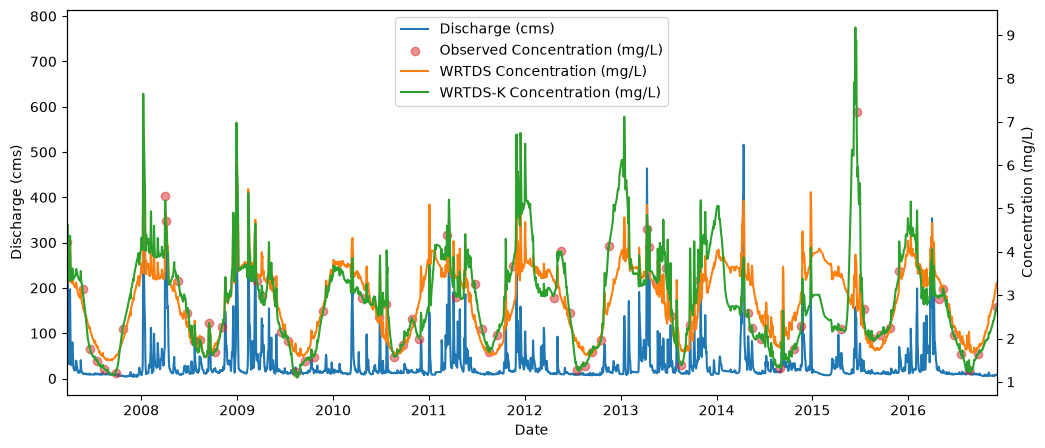

In [9]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(y_hat_q.index, y_hat_q['Q'], label='Discharge (cms)')
ax2 = ax.twinx()
ax2.scatter(df_wq.index, df_wq['Conc'], label='Observed Concentration (mg/L)', color='tab:red', alpha=0.5)
ax2.plot(y_hat_q.index, y_hat_q['ConcHat'], label='WRTDS Concentration (mg/L)', color='tab:orange')
ax2.plot(df_q_k.index, df_q_k['ConcKalman'], label='WRTDS-K Concentration (mg/L)', color='tab:green')
ax.set_xlabel('Date')
ax.set_ylabel('Discharge (cms)')
ax2.set_ylabel('Concentration (mg/L)')
for sub_ax in [ax, ax2]:
    sub_ax.set_xlim(df_wq.index.min(), df_wq.index.max())
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2)
plt.show()